In [1]:
# ── Run to analyse: a folder name under output/, or a full path ─────────────
# run_04 is the run of the current set-up (4-D broken power law
# pw = [log10(A), n1, n2, log10(k_break)], AA*, config.yml as it is now).
# The next cell refuses a run whose graph / buffer / sampling settings differ from config.yml.
RUN_NAME = "run_04"


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import corner
from pathlib import Path

# Project root (this notebook lives in notebooks/) — single-run analysis.
HERE     = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists())
DATA_DIR = HERE / "data"

# Resolve run dir: accept a bare name or a full/relative path.
run_path = Path(RUN_NAME)
if not run_path.exists():
    run_path = HERE / "output" / RUN_NAME
run_path = run_path.resolve()

# Only analyse a run of the current set-up: its graph, buffer and sampling settings must equal
# config.yml (paths and logging may differ). Older runs used other skies, priors or noise models.
import yaml
_run_cfg = yaml.safe_load((run_path / "config.yml").read_text())
_cur_cfg = yaml.safe_load((HERE / "config.yml").read_text())
for _key in ("graph", "buffer", "sample"):
    assert _run_cfg[_key] == _cur_cfg[_key], \
        f"{run_path.name}: '{_key}' differs from config.yml -- not a run of the current set-up"

SAMPLES_DIR = run_path / "samples" / "posterior"
assert SAMPLES_DIR.exists(), f"Samples directory not found: {SAMPLES_DIR}"

files      = sorted(SAMPLES_DIR.glob("*.npz"))
pw_samples = np.stack([np.load(f)["pw"] for f in files])   # (N, 4)
z_samples  = np.stack([np.load(f)["z"]  for f in files])   # (N, n_z)
print(f"[{RUN_NAME}] {len(files)} posterior samples")
print(f"  pw_shape={pw_samples.shape}   z_shape={z_samples.shape}")

# True parameters — true_pw.npy is now 4-D
true_pw = np.load(DATA_DIR / "true_pw.npy").squeeze()
true_z  = np.load(DATA_DIR / "true_z.npy").squeeze()
assert true_pw.shape[-1] == 4, (
    f"Expected 4-D true_pw for broken PL, got {true_pw.shape}. "
    f"Re-run scripts/gen_mock_data.py."
)
print(f"True pw: log10(A)={true_pw[0]:+.3f}  n1={true_pw[1]:+.3f}  "
      f"n2={true_pw[2]:+.3f}  log10(k_break)={true_pw[3]:+.3f}")

# Broken-PL parameter names (4-D)
pw_names = [
    r"$\log_{10}(A)$",
    r"$n_1$",
    r"$n_2$",
    r"$\log_{10}(k_{\mathrm{break}})$",
]
n_z = z_samples.shape[1]
# z are the gain PERTURBATIONS of the unknown antennas k = 1, 2, ...: g_k = 1 + z_Re + i z_Im
z_names = [
    rf"$\mathrm{{Re}}\,g_{{{i//2+1}}} - 1$" if i % 2 == 0 else rf"$\mathrm{{Im}}\,g_{{{i//2+1}}}$"
    for i in range(n_z)
]

label = run_path.name
COL   = "steelblue"

[run_04] 1500 posterior samples
  pw_shape=(1500, 4)   z_shape=(1500, 212)
True pw: log10(A)=-1.800  n1=-2.000  n2=-3.000  log10(k_break)=-0.300


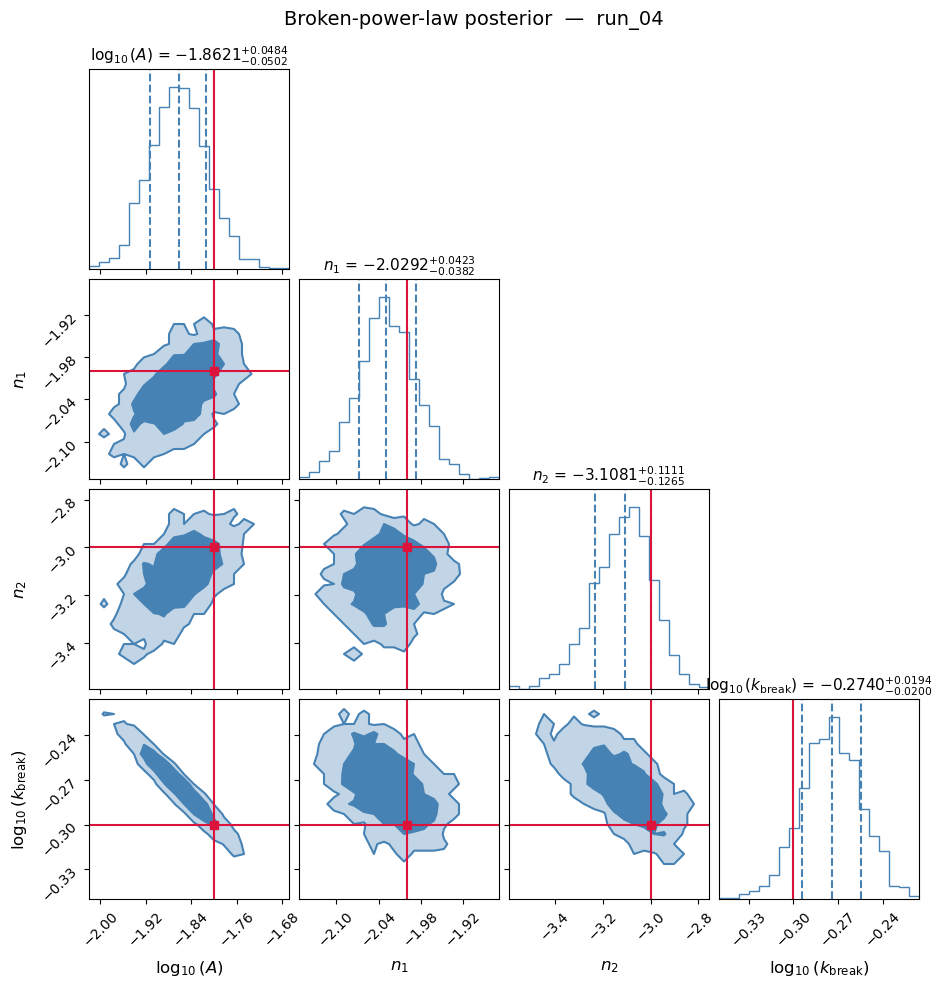

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/posterior_corner_pw.pdf


In [3]:
# pw 4-D corner: [log10(A), n1, n2, log10(k_break)]
fig = corner.corner(
    pw_samples,
    labels=pw_names,
    truths=true_pw,
    truth_color="crimson",
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".4f",
    title_kwargs={"fontsize": 11},
    label_kwargs={"fontsize": 12},
    color=COL,
    fill_contours=True,
    levels=(0.683, 0.954),
    plot_datapoints=False,
)
fig.suptitle(f"Broken-power-law posterior  —  {label}", fontsize=14, y=1.02)
out_pw = run_path / "posterior_corner_pw.pdf"
plt.savefig(out_pw, bbox_inches="tight")
plt.show()
print(f"Saved: {out_pw}")

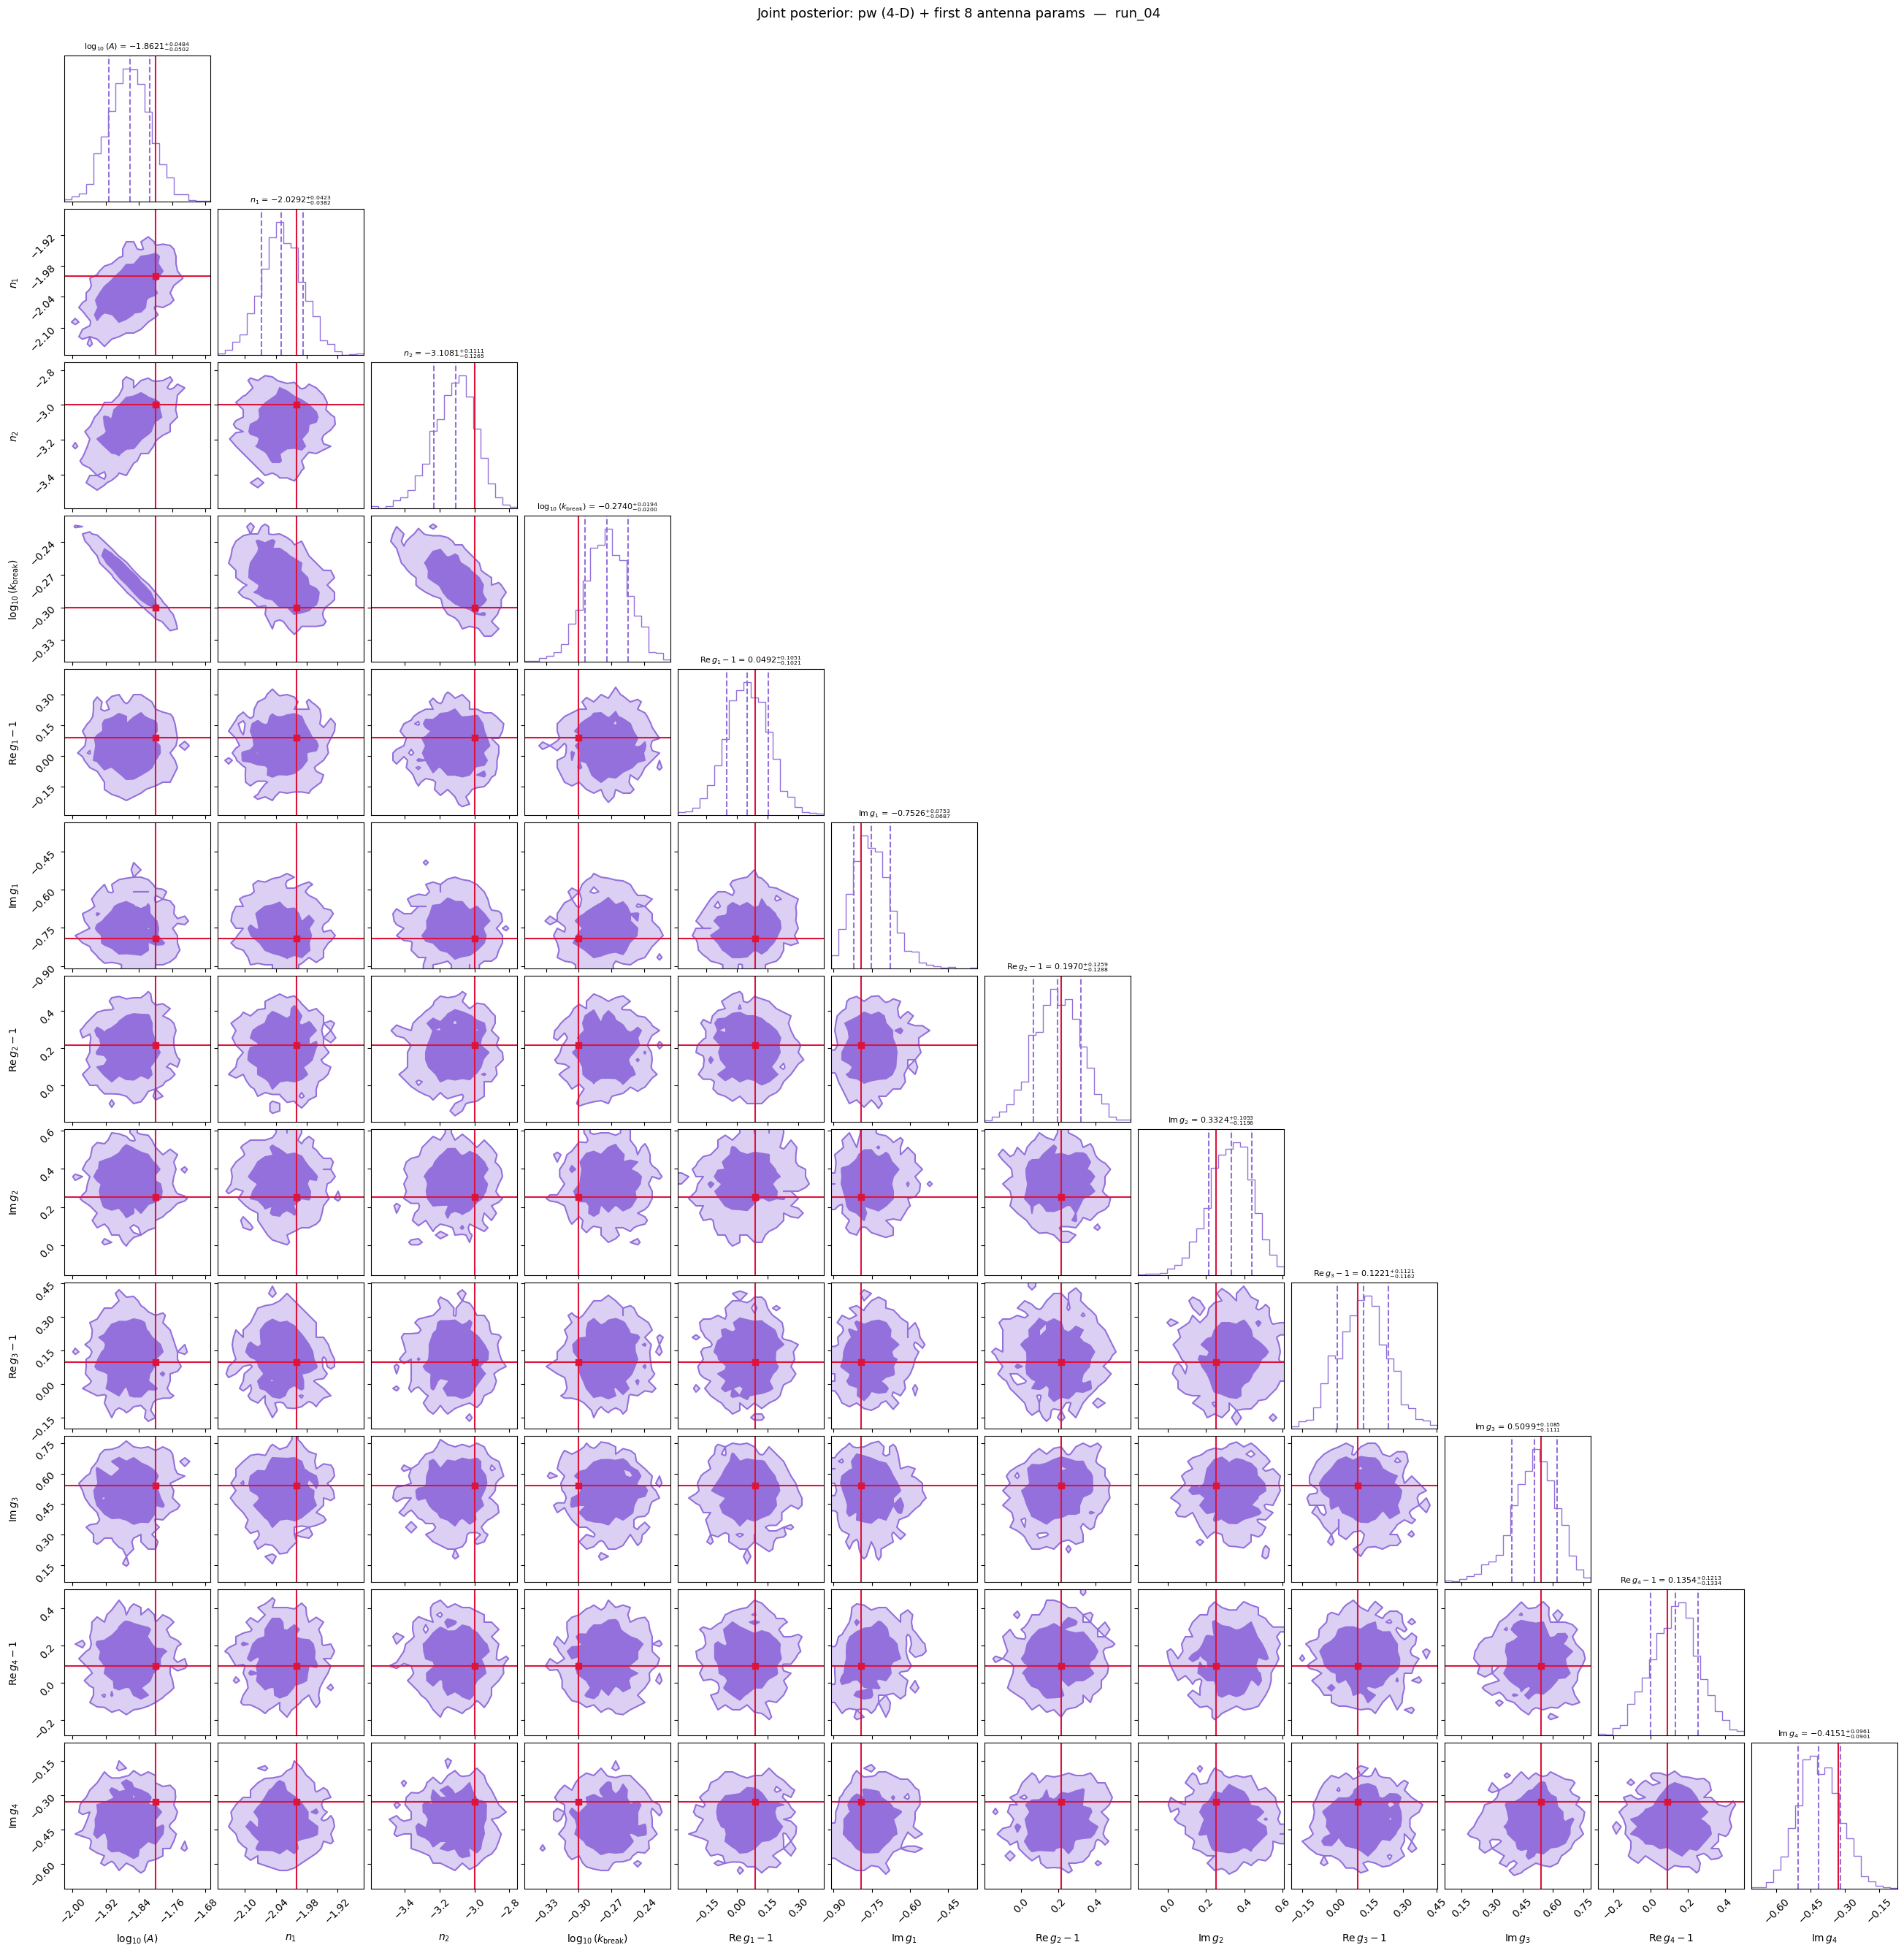

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/posterior_corner_joint_pw_z8.pdf


In [4]:
# Joint corner: 4 pw + first n_ant z parameters
n_ant = 8  # first 8 z params: Re g_1 - 1, Im g_1, ..., Re g_4 - 1, Im g_4

joint_samples = np.concatenate([pw_samples, z_samples[:, :n_ant]], axis=1)
joint_labels  = pw_names + z_names[:n_ant]
joint_truths  = np.concatenate([true_pw, true_z[:n_ant]])

fig = corner.corner(
    joint_samples,
    labels=joint_labels,
    truths=joint_truths,
    truth_color="crimson",
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".4f",
    title_kwargs={"fontsize": 8},
    label_kwargs={"fontsize": 10},
    color="mediumpurple",
    fill_contours=True,
    levels=(0.683, 0.954),
    plot_datapoints=False,
)
fig.suptitle(f"Joint posterior: pw (4-D) + first {n_ant} antenna params  —  {label}",
             fontsize=13, y=1.01)
out_joint = run_path / f"posterior_corner_joint_pw_z{n_ant}.pdf"
plt.savefig(out_joint, bbox_inches="tight")
plt.show()
print(f"Saved: {out_joint}")

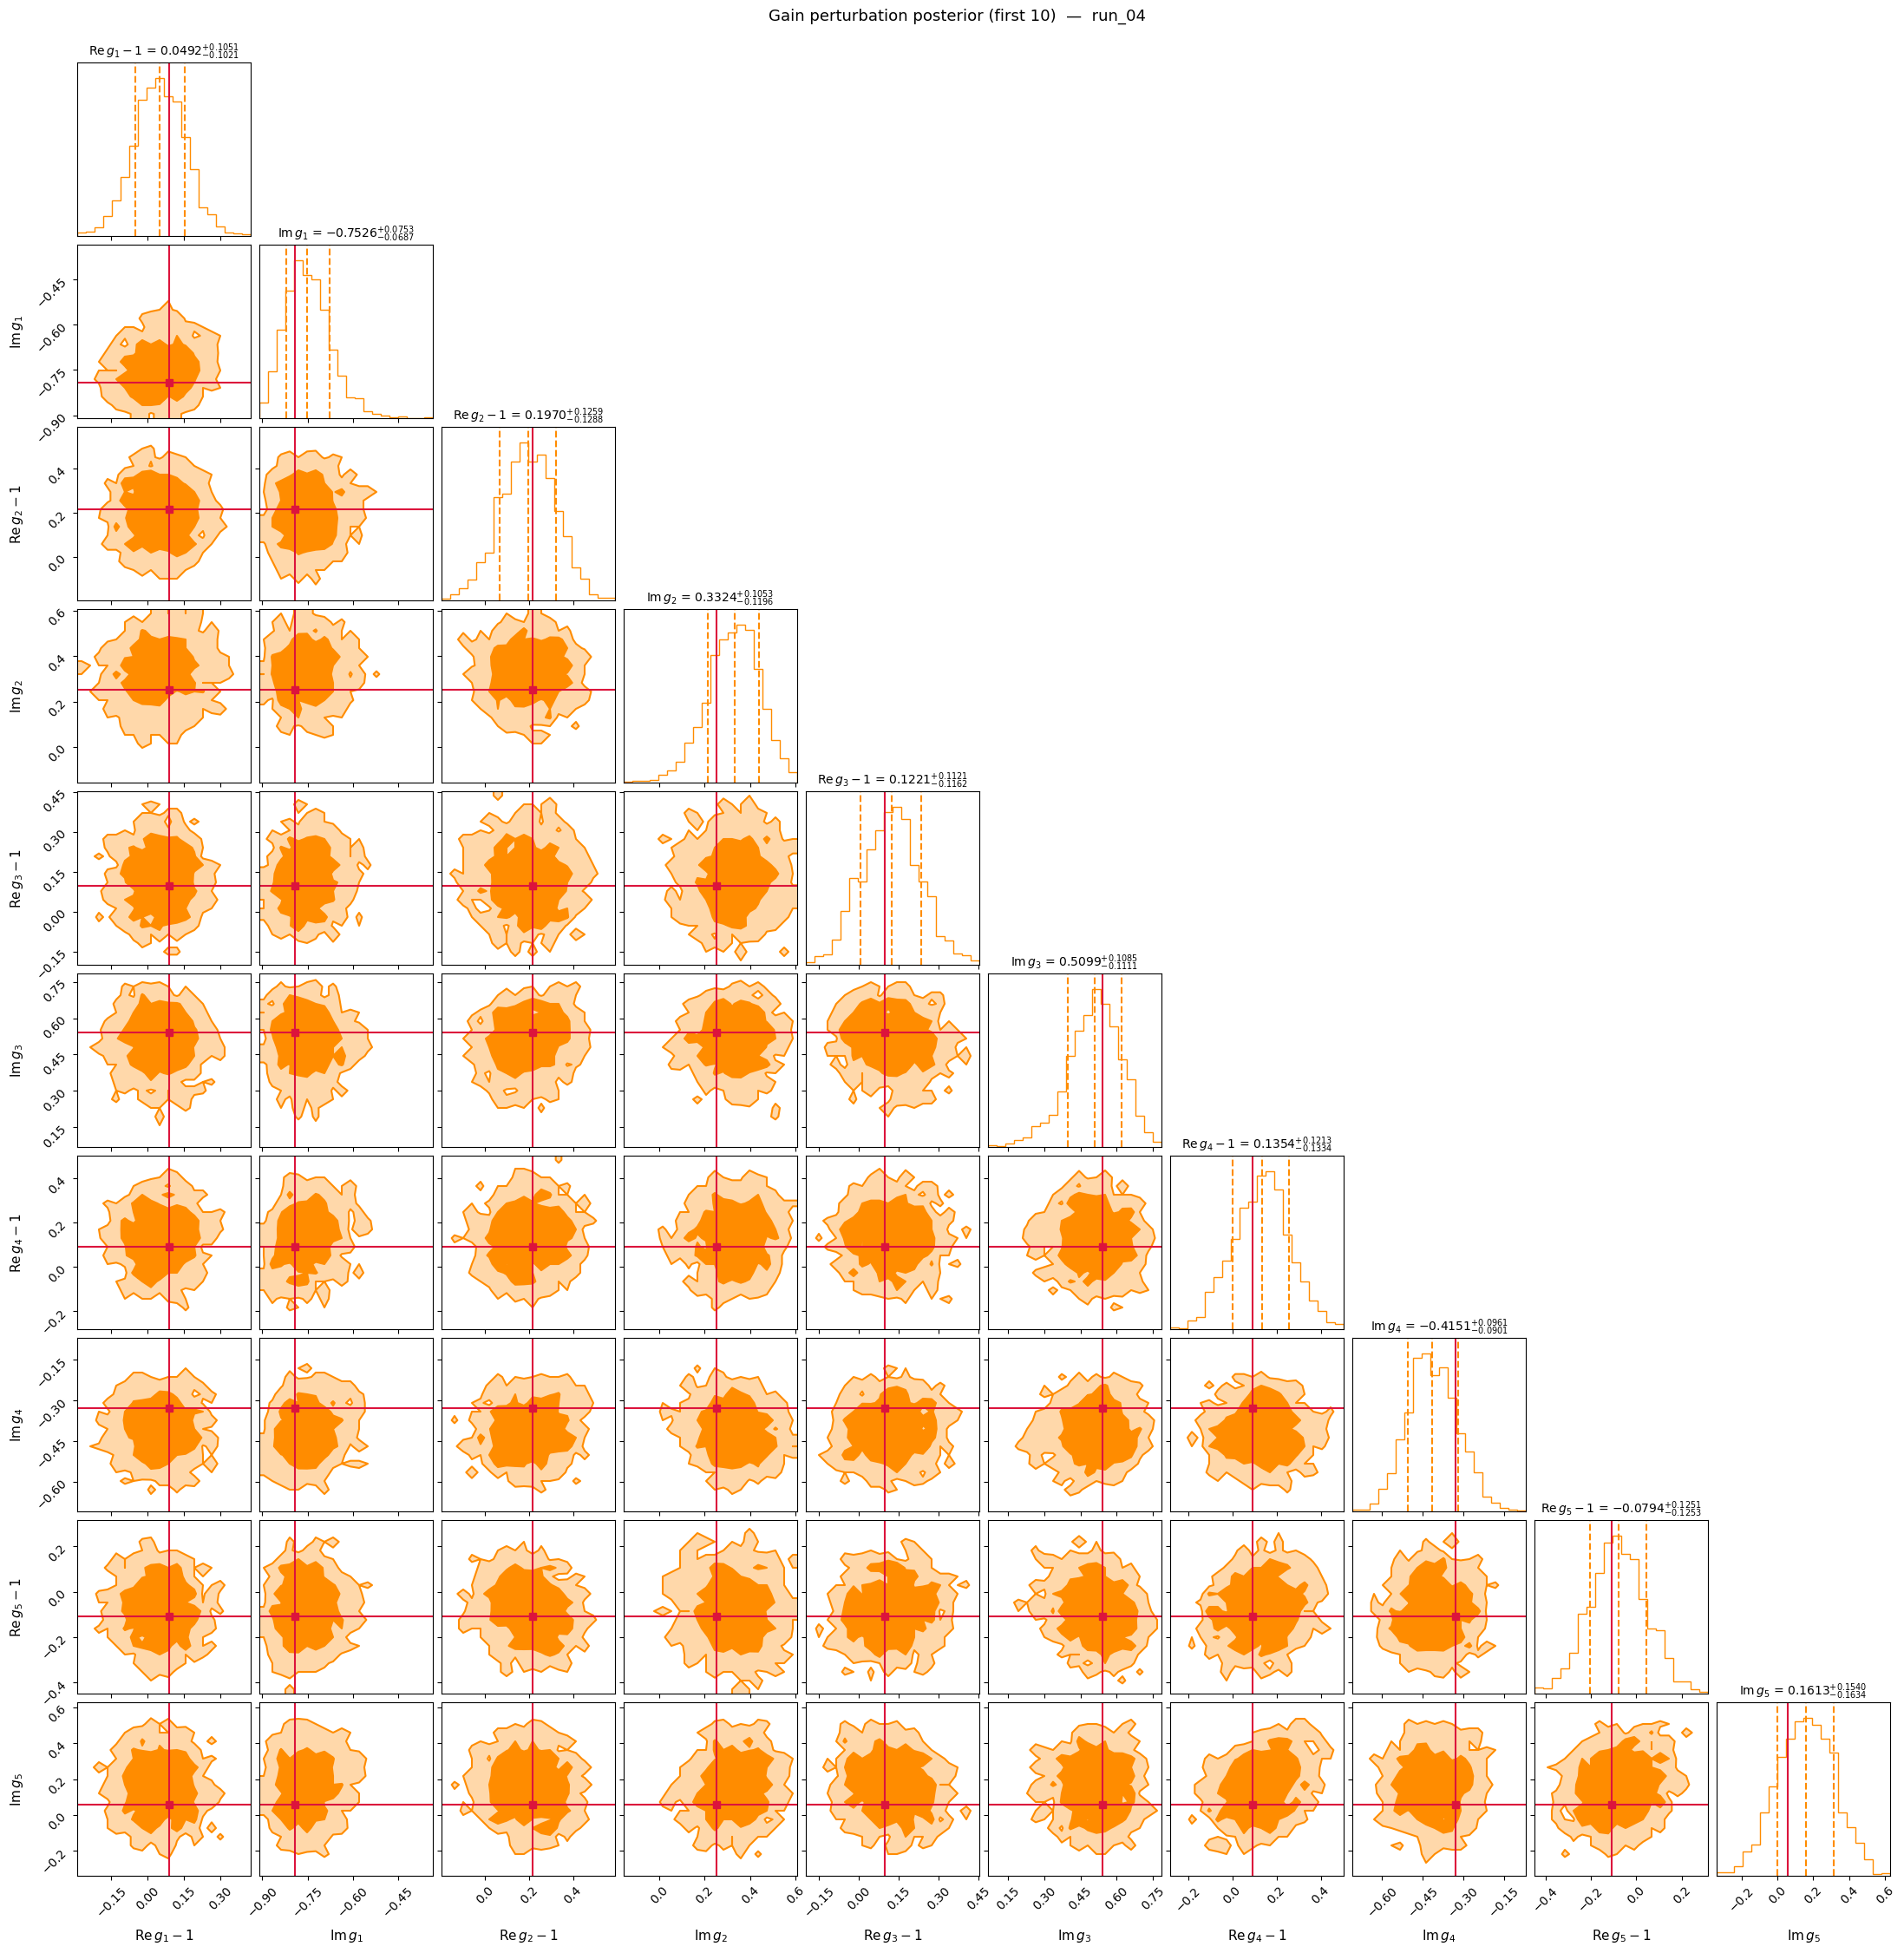

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/posterior_corner_z.pdf


In [5]:
# Gain-perturbation z corner (first 10)
n_z_show = 10
fig = corner.corner(
    z_samples[:, :n_z_show],
    labels=z_names[:n_z_show],
    truths=true_z[:n_z_show],
    truth_color="crimson",
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".4f",
    title_kwargs={"fontsize": 10},
    label_kwargs={"fontsize": 11},
    color="darkorange",
    fill_contours=True,
    levels=(0.683, 0.954),
    plot_datapoints=False,
)
fig.suptitle(f"Gain perturbation posterior (first {n_z_show})  —  {label}",
             fontsize=13, y=1.01)
out_z = run_path / "posterior_corner_z.pdf"
plt.savefig(out_z, bbox_inches="tight")
plt.show()
print(f"Saved: {out_z}")

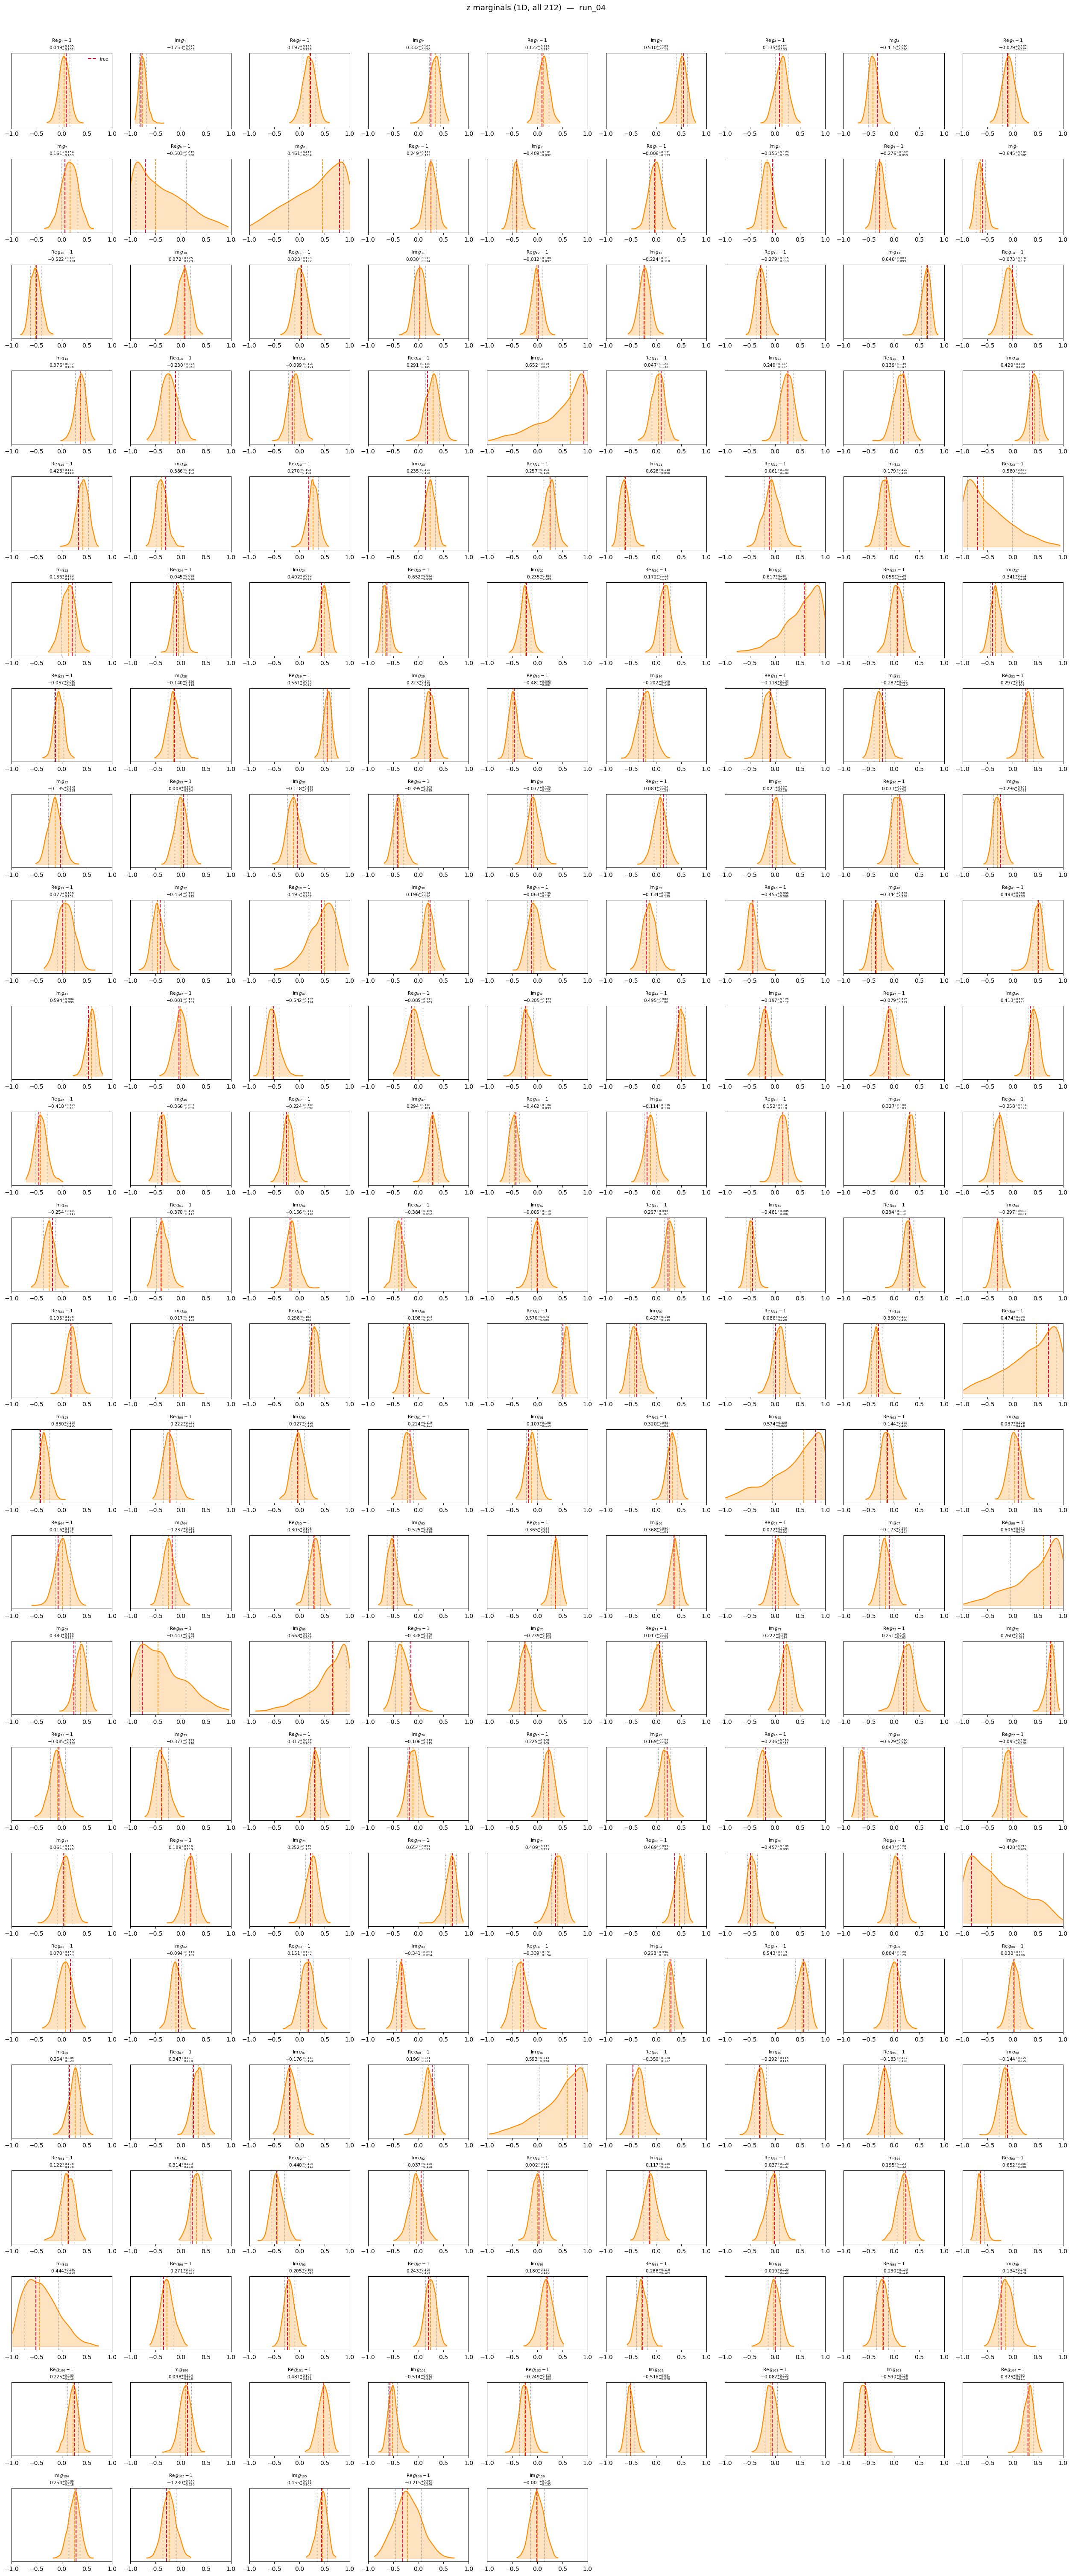

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/posterior_1d_z.pdf


In [6]:
# 1D z marginals (all n_z) — single-run KDE per parameter
from scipy.stats import gaussian_kde

n_z   = z_samples.shape[1]
ncols = 9
nrows = int(np.ceil(n_z / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.8, nrows * 2.5))
axes = axes.flat

for i in range(n_z):
    ax = axes[i]
    x  = z_samples[:, i]

    xs  = np.linspace(x.min(), x.max(), 500)
    kde = gaussian_kde(x)
    ax.plot(xs, kde(xs), color="darkorange", lw=1.5)
    ax.fill_between(xs, kde(xs), alpha=0.25, color="darkorange")

    med    = np.median(x)
    lo, hi = np.percentile(x, [16, 84])
    ax.axvline(true_z[i], color="crimson",    lw=1.5, ls="--", label="true")
    ax.axvline(med,        color="darkorange", lw=1.2, ls="--")
    ax.axvline(lo,         color="gray",       lw=0.9, ls=":")
    ax.axvline(hi,         color="gray",       lw=0.9, ls=":")
    ax.set_xlim(-1, 1)
    title = f"{z_names[i]}\n${med:.3f}^{{+{hi-med:.3f}}}_{{-{med-lo:.3f}}}$"
    ax.set_title(title, fontsize=7.5)
    ax.set_yticks([])
    if i == 0:
        ax.legend(fontsize=7, frameon=False)

for j in range(n_z, nrows * ncols):
    axes[j].set_visible(False)

fig.suptitle(f"z marginals (1D, all {n_z})  —  {label}", fontsize=13, y=1.005)
plt.tight_layout()
out_z1d = run_path / "posterior_1d_z.pdf"
plt.savefig(out_z1d, bbox_inches="tight")
plt.show()
print(f"Saved: {out_z1d}")

In [7]:
# Summary table — median ± 68% band for each parameter
def _summary(x):
    m  = np.median(x)
    lo, hi = np.percentile(x, [16, 84])
    return m, hi - m, m - lo

def _fmt(arr, i):
    m, p, n = _summary(arr[:, i])
    return f"{m:+.4f} (+{p:.4f} / -{n:.4f})"

print(f"{'param':<28} {label:>40}      truth")
print("=" * 88)

print("--- pw (broken power law: log10(A), n1, n2, log10(k_break)) ---")
for i, name in enumerate(pw_names):
    print(f"{name:<28} {_fmt(pw_samples, i):>40}   {true_pw[i]:+.4f}")

print("\n--- z (gain perturbations) ---")
for i, name in enumerate(z_names):
    print(f"{name:<28} {_fmt(z_samples, i):>40}   {true_z[i]:+.4f}")

param                                                          run_04      truth
--- pw (broken power law: log10(A), n1, n2, log10(k_break)) ---
$\log_{10}(A)$                            -1.8621 (+0.0484 / -0.0502)   -1.8000
$n_1$                                     -2.0292 (+0.0423 / -0.0382)   -2.0000
$n_2$                                     -3.1081 (+0.1111 / -0.1265)   -3.0000
$\log_{10}(k_{\mathrm{break}})$              -0.2740 (+0.0194 / -0.0200)   -0.3000

--- z (gain perturbations) ---
$\mathrm{Re}\,g_{1} - 1$                  +0.0492 (+0.1051 / -0.1021)   +0.0898
$\mathrm{Im}\,g_{1}$                      -0.7526 (+0.0753 / -0.0687)   -0.7929
$\mathrm{Re}\,g_{2} - 1$                  +0.1970 (+0.1259 / -0.1288)   +0.2170
$\mathrm{Im}\,g_{2}$                      +0.3324 (+0.1053 / -0.1196)   +0.2517
$\mathrm{Re}\,g_{3} - 1$                  +0.1221 (+0.1121 / -0.1162)   +0.0961
$\mathrm{Im}\,g_{3}$                      +0.5099 (+0.1085 / -0.1111)   +0.5403
$\mathrm{Re}\,g_{4} 

z (212 params): corr(median, truth) = 0.976   rms(median - truth) = 0.0749
  truth inside the 68 % interval for 98.6% of the parameters (68 % if calibrated)
  mean 68 % half-width = 0.1382   vs rms error = 0.0749


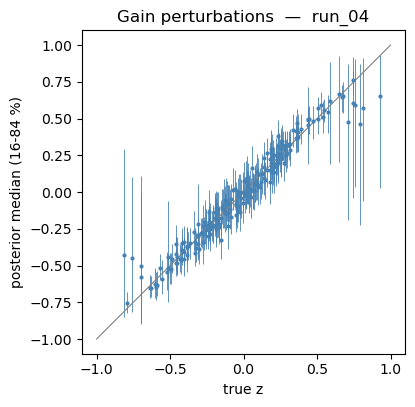

In [8]:
# Gain posterior vs truth (Stage 1): accuracy of the medians and calibration of the widths.
# With NOISE_STD = 0 the gains are exactly recoverable from V_ref (imageanalysis.ipynb), so the
# widths reflect the trained network, not the information in the data.
z_med        = np.median(z_samples, axis=0)
z_lo, z_hi   = np.percentile(z_samples, [16, 84], axis=0)
corr         = np.corrcoef(z_med, true_z)[0, 1]
rms_err      = np.sqrt(np.mean((z_med - true_z) ** 2))
inside_68    = np.mean((true_z >= z_lo) & (true_z <= z_hi))
half_width   = 0.5 * (z_hi - z_lo)
print(f"z ({n_z} params): corr(median, truth) = {corr:.3f}   rms(median - truth) = {rms_err:.4f}")
print(f"  truth inside the 68 % interval for {inside_68:.1%} of the parameters (68 % if calibrated)")
print(f"  mean 68 % half-width = {half_width.mean():.4f}   vs rms error = {rms_err:.4f}")

fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.errorbar(true_z, z_med, yerr=[z_med - z_lo, z_hi - z_med], fmt=".", ms=4, lw=0.6, color=COL)
ax.plot([-1, 1], [-1, 1], color="gray", lw=0.8)
ax.set(xlabel="true z", ylabel="posterior median (16-84 %)", title=f"Gain perturbations  —  {label}",
       aspect="equal")
plt.show()

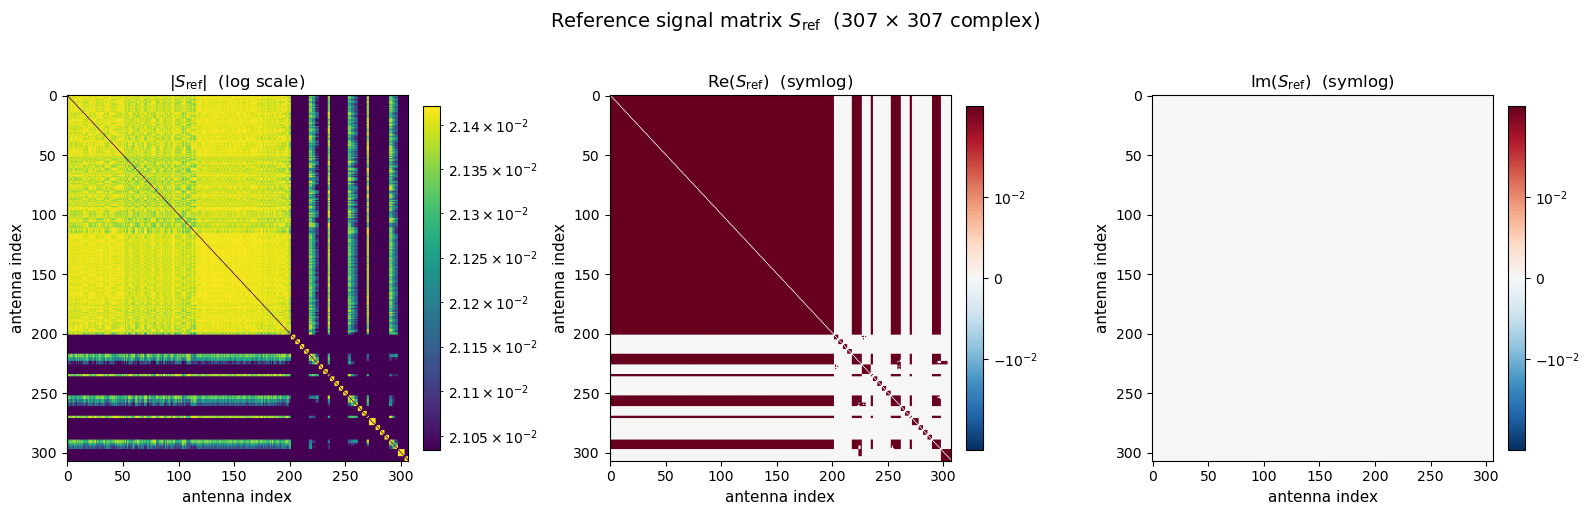

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/figures/S_ref_colorplot.pdf


In [9]:
import matplotlib.colors as mcolors

S_ref = np.load(DATA_DIR / "S_ref.npy")   # (N, N) complex

amp  = np.abs(S_ref)
real = S_ref.real
imag = S_ref.imag

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# amplitude: LogNorm — floor at the 1st percentile of non-zero |S| to avoid log(0)
# (S is averaged over each baseline's integrations, so values are O(1e-2) mK)
amp_floor = float(np.percentile(amp[amp > 0], 1.0))
amp_clipped = np.clip(amp, amp_floor, None)
norm_amp = mcolors.LogNorm(vmin=amp_floor, vmax=amp.max())

# real / imaginary: SymLogNorm — linear near zero, log for large values
linthresh = amp_floor
norm_sym = mcolors.SymLogNorm(linthresh=linthresh, linscale=1.0,
                               vmin=-amp.max(), vmax=amp.max(), base=10)

panels = [
    (axes[0], amp_clipped,  norm_amp, "viridis",
     r"$|S_{\mathrm{ref}}|$  (log scale)"),
    (axes[1], real,          norm_sym, "RdBu_r",
     r"$\mathrm{Re}(S_{\mathrm{ref}})$  (symlog)"),
    (axes[2], imag,          norm_sym, "RdBu_r",
     r"$\mathrm{Im}(S_{\mathrm{ref}})$  (symlog)"),
]

for ax, d, norm, cmap, title in panels:
    im = ax.imshow(d, origin="upper", aspect="auto", cmap=cmap, norm=norm)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("antenna index", fontsize=11)
    ax.set_ylabel("antenna index", fontsize=11)

fig.suptitle(rf"Reference signal matrix $S_{{\mathrm{{ref}}}}$  ({S_ref.shape[0]} × {S_ref.shape[1]} complex)", fontsize=14, y=1.02)
plt.tight_layout()
out = HERE / "figures" / "S_ref_colorplot.pdf"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")


In [10]:
# ── Shared setup for the buffer/posterior analysis cells below ─────────────
# Done once and reused by every later cell:
#   • simulators       : pw_sim, dense
#   • truths           : true_delta, S_true, true_k, true_pk
#   • file lists / pw  : buffer_files, posterior_files, pw_buffer, pw_post
#   • strided preload  : pw_strided_buf, uv_strided_buf, pk_strided_buf
#   • helpers          : fig_to_pil, save_and_show_gif (LOOPING by default),
#                        regen_df (broken-PL: A, n1, n2, k_break),
#                        regen_S_from_uv,
#                        pk_theory_broken (broken-PL analytical, matches measurer norm),
#                        make_df_gif, make_S_gif (ratio panel),
#                        make_pk_gif (buffer: measured + analytical overlay),
#                        make_pk_post_gif (posterior: analytical only)
import sys, io
import numpy as np
import torch
import matplotlib.colors as mcolors
from PIL import Image
from IPython.display import Image as IPyImage, display

SRC_DIR = HERE / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import functionlistnew as func  # noqa: E402
import settings                 # noqa: E402

device = "cuda" if torch.cuda.is_available() else "cpu"
# Fields at the truth's seed must be drawn on the device that made data/ (torch draws different random
# numbers on CPU and GPU for the same seed): data/mock_device.npy, written by scripts/gen_mock_data.py.
MOCK_DEVICE  = str(np.load(DATA_DIR / "mock_device.npy"))
regen_device = MOCK_DEVICE if (MOCK_DEVICE == "cpu" or torch.cuda.is_available()) else "cpu"
SHAPE, SEED = settings.N_PIX, settings.TRUE_FIELD_SEED
SHOW_GIFS = False    # True: also embed every GIF in the notebook (always saved to run_path)
STRIDE_BUFFER_GIF = 20   # used by every buffer GIF below

cfg    = func.SimulationConfig(shape=SHAPE, device=regen_device)   # BoxSize etc.: src/settings.py
pw_sim = func.DensityField2D(cfg)
padded = torch.load(settings.PADDED_PATH, map_location=device, weights_only=True)
NANT   = func.nant_from_padded(padded)   # 46971 baselines -> 307 antennas
dense  = func.SkyMatrixGenerator(padded, SHAPE, NANT)

true_delta = np.load(DATA_DIR / "true_delta.npy").squeeze()       # (H, W)
S_true     = np.load(DATA_DIR / "S_obs.npy").squeeze()            # (N, N)
true_k     = np.load(DATA_DIR / "true_k.npy")                     # (50,)
true_pk    = np.load(DATA_DIR / "true_pk_measured.npy")           # (50,) — measured

BUFFER_DIR      = run_path / "samples" / "buffer"
POSTERIOR_DIR   = run_path / "samples" / "posterior"
buffer_files    = sorted(BUFFER_DIR.glob("*.npz"))
posterior_files = sorted(POSTERIOR_DIR.glob("*.npz"))

pw_buffer = np.stack([np.load(f)["pw.value"] for f in buffer_files])   # (Nb, 4)
pw_post   = np.stack([np.load(f)["pw"]       for f in posterior_files]) # (Np, 4)
print(f"buffer files: {len(buffer_files)}   pw_buffer: {pw_buffer.shape}")
print(f"posterior files: {len(posterior_files)}   pw_post:  {pw_post.shape}")
assert pw_buffer.shape[-1] == 4 and pw_post.shape[-1] == 4, (
    "Expected 4-D pw — re-run with the broken-PL config first."
)

# Single strided pass — every key the buffer GIFs need, one np.load per file.
strided_buf_files = buffer_files[::STRIDE_BUFFER_GIF]
uv_strided_buf, pk_strided_buf = [], []
for f in strided_buf_files:
    with np.load(f) as d:
        uv_strided_buf.append(d["uvimage.value"].astype(np.complex64))
        pk_strided_buf.append(d["pk_df.value"])
uv_strided_buf = np.stack(uv_strided_buf)                  # (F, 128, 128) complex64
pk_strided_buf = np.stack(pk_strided_buf)                  # (F, 50)
pw_strided_buf = pw_buffer[::STRIDE_BUFFER_GIF]            # (F, 4)
print(f"strided buffer (stride={STRIDE_BUFFER_GIF}): "
      f"pw {pw_strided_buf.shape}  uv {uv_strided_buf.shape}  pk {pk_strided_buf.shape}")


def fig_to_pil(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert("P", palette=Image.ADAPTIVE)


def save_and_show_gif(frames, path, duration=250, loop=0):
    """`loop=0` → infinite loop (default). Pass `loop=1` for play-once."""
    frames[0].save(path, save_all=True, append_images=frames[1:],
                   duration=duration, optimize=True, loop=loop)
    print(f"Saved GIF: {path}  ({path.stat().st_size/1e6:.1f} MB, "
          f"{len(frames)} frames, loop={loop})")
    if SHOW_GIFS:
        display(IPyImage(filename=str(path)))


def _pw_title(pw):
    """Compact 4-param label for GIF frame titles."""
    return (rf"$\log_{{10}}(A)={pw[0]:.2f}$, $n_1={pw[1]:.2f}$, "
            rf"$n_2={pw[2]:.2f}$, $\log_{{10}}(k_b)={pw[3]:.2f}$")


# ── Analytical broken-PL, in the measurer's convention ─────────────────────
# Generator: <|δ̃_ortho|²> = power_spectrum_2d(k) / (dx*dy).
# Measurer reports |δ̃_ortho|² * dx*dy, so <P_measured(k)> = power_spectrum_2d(k)
# at any BoxSize: no extra factor.


def pk_theory_broken(k, pw):
    """Broken power law evaluated at k for one pw=[log10(A), n1, n2, log10(k_break)],
    in the measurer's convention (no extra factor)."""
    k = np.asarray(k, dtype=float)
    A      = 10.0 ** float(pw[0])
    n1, n2 = float(pw[1]), float(pw[2])
    kb     = 10.0 ** float(pw[3])
    ratio  = k / kb
    pk = np.where(k <= kb, A * ratio ** n1, A * ratio ** n2)
    return pk


def regen_df(pw_arr, seed=SEED):
    """Regenerate density fields for each broken-PL pw at fixed seed.
    pw_arr shape: (F, 4) — [log10(A), n1, n2, log10(k_break)]."""
    out = []
    with torch.no_grad():
        for pw in pw_arr:
            pw_t = torch.tensor(np.asarray(pw)[None], device=regen_device, dtype=torch.float32)
            df = pw_sim.sample_field(*func.pw_to_params(pw_t), seed=seed)   # as model.DensityFromPw
            out.append(df[0].detach().cpu().numpy())
    return np.stack(out)


def regen_S_from_uv(uv_arr):
    """Run SkyMatrixGenerator on a pre-loaded (F, H, W) complex uvimage array."""
    out = []
    with torch.no_grad():
        for uv in uv_arr:
            uv_t = torch.tensor(uv, dtype=torch.complex64, device=device).unsqueeze(0)
            out.append(dense(uv_t)[0].detach().cpu().numpy())
    return np.stack(out)


def make_df_gif(pw_frames, label, out_name):
    """3-panel GIF: true δ | sampled δ | (true − sampled), all on the same vlim."""
    dfs  = regen_df(pw_frames)
    vlim = float(np.max(np.abs(true_delta)))
    def render(df, pw, idx, total):
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), dpi=100)
        for ax, data, title in [
            (axes[0], true_delta,       r"true $\delta$"),
            (axes[1], df,               rf"{label} $\delta$ (seed={SEED})"),
            (axes[2], true_delta - df,  rf"true $-$ {label}"),
        ]:
            im = ax.imshow(data, origin="upper", cmap="RdBu_r",   # array[y, x], as in figures/
                           vmin=-vlim, vmax=vlim)
            ax.set_title(title, fontsize=11)
            ax.set_xticks([]); ax.set_yticks([])
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.suptitle(rf"{label} frame {idx+1}/{total}   " + _pw_title(pw),
                     fontsize=10, y=1.02)
        fig.tight_layout()
        return fig_to_pil(fig)
    frames = [render(dfs[i], pw_frames[i], i, len(dfs)) for i in range(len(dfs))]
    save_and_show_gif(frames, run_path / out_name)


def make_S_gif(uv_arr, label, out_name, ratio_decades=0.5):
    """3-panel GIF: |S_true| (log) | |S_dense| (log) |
                    log10(|S_dense| / |S_true|)  ←  RATIO panel (diverging).

    Ratio is masked where |S_true| < amp_floor (no meaningful comparison there).
    `ratio_decades` is the half-range of the log10-ratio colour scale (default
    ±0.5 dex; tighten/loosen depending on how close sample is to truth).
    """
    S_seq    = regen_S_from_uv(uv_arr)
    amp_true = np.abs(S_true)
    amp_pos  = amp_true[amp_true > 0]
    amp_floor = float(np.percentile(amp_pos, 1.0))   # S is track-averaged, O(1e-2)
    amp_vmax  = float(np.percentile(amp_true, 99.5))
    norm_amp  = mcolors.LogNorm(vmin=amp_floor, vmax=amp_vmax)

    def render(S, idx, total):
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), dpi=100)
        amp_S = np.abs(S)
        for ax, data, title in [
            (axes[0], amp_true, r"true $|S|$"),
            (axes[1], amp_S,    rf"{label} $|S_\mathrm{{dense}}|$"),
        ]:
            im = ax.imshow(np.clip(data, amp_floor, None),
                           origin="upper", aspect="auto",
                           cmap="viridis", norm=norm_amp)
            ax.set_title(title, fontsize=11)
            ax.set_xlabel("antenna index", fontsize=10)
            ax.set_ylabel("antenna index", fontsize=10)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        valid = amp_true >= amp_floor
        ratio = np.where(valid,
                         amp_S / np.maximum(amp_true, 1e-30),
                         np.nan)
        log_ratio = np.log10(np.clip(ratio, 10.0 ** (-3 * ratio_decades),
                                     10.0 ** ( 3 * ratio_decades)))
        cmap = plt.get_cmap("RdBu_r").copy()
        cmap.set_bad("0.85")
        im = axes[2].imshow(log_ratio, origin="upper", aspect="auto",
                            cmap=cmap, vmin=-ratio_decades, vmax=+ratio_decades)
        axes[2].set_title(rf"$\log_{{10}}(|S_\mathrm{{{label}}}| / |S_\mathrm{{true}}|)$",
                          fontsize=11)
        axes[2].set_xlabel("antenna index", fontsize=10)
        plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04,
                     label=f"dex  (±{ratio_decades})")

        fig.suptitle(rf"$S_\mathrm{{dense}}$ {label} frame {idx+1}/{total}",
                     fontsize=11, y=1.02)
        fig.tight_layout()
        return fig_to_pil(fig)
    frames = [render(S_seq[i], i, len(S_seq)) for i in range(len(S_seq))]
    save_and_show_gif(frames, run_path / out_name)


def _pk_axis_limits(*arrs):
    """Robust [lo, hi] for log-y from positive, finite P(k) values."""
    vals = np.concatenate([a[np.isfinite(a) & (a > 0)] for a in arrs])
    if vals.size == 0:
        return 1e-30, 1.0
    return float(np.percentile(vals, 1)) * 0.5, float(np.percentile(vals, 99)) * 2.0


def make_pk_gif(pk_seq, pw_arr, label, out_name):
    """3-panel GIF (for buffer samples where measured pk_df is stored):
        | true measured P(k)
        | this frame's measured + true measured (dashed) + ANALYTICAL from pw (dot-dash)
        | ratios   measured/true (steelblue)   AND   analytical/true (seagreen, dot-dash)
    The analytical curve is the broken-PL given by this frame's pw, evaluated on
    `true_k` and scaled to the measurer's convention via pk_theory_broken().
    """
    # Pre-compute analytical curves for axis limits and per-frame plotting.
    pk_theory_seq = np.stack([pk_theory_broken(true_k, pw) for pw in pw_arr])
    pk_lo, pk_hi  = _pk_axis_limits(true_pk, pk_seq, pk_theory_seq)

    def render(pk_one, pk_th, pw, idx, total):
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), dpi=100)
        # Left
        axes[0].loglog(true_k, true_pk, color="crimson", lw=1.6)
        axes[0].set_title(r"true measured $P(k)$", fontsize=11)
        # Middle
        axes[1].loglog(true_k, true_pk, color="crimson",   lw=1.0, ls="--", alpha=0.6,
                       label="true measured")
        axes[1].loglog(true_k, pk_one,  color="steelblue", lw=1.6,
                       label=f"{label} measured")
        axes[1].loglog(true_k, pk_th,   color="seagreen",  lw=1.4, ls="-.",
                       label=f"{label} analytical")
        kb = 10.0 ** pw[3]
        for ax in axes[:2]:
            ax.axvline(kb, color="gray", lw=0.9, ls=":")
        axes[1].set_title(rf"{label} $P(k)$", fontsize=11)
        axes[1].legend(fontsize=8, frameon=False)
        # Right
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio_meas = pk_one / true_pk
            ratio_th   = pk_th  / true_pk
        axes[2].semilogx(true_k, ratio_meas, color="steelblue", lw=1.6,
                         label=f"{label} measured / true")
        axes[2].semilogx(true_k, ratio_th,   color="seagreen",  lw=1.4, ls="-.",
                         label=f"{label} analytical / true")
        axes[2].axhline(1.0, color="crimson", ls="--", lw=1.0)
        axes[2].set_title("ratios vs true measured", fontsize=11)
        axes[2].set_ylim(0, 3)
        axes[2].legend(fontsize=8, frameon=False)
        for ax in axes[:2]:
            ax.set_ylim(pk_lo, pk_hi)
        for ax in axes:
            ax.set_xlabel(r"$k$", fontsize=10)
            ax.grid(alpha=0.3, which="both")
        axes[0].set_ylabel(r"$P(k)$", fontsize=10)
        axes[2].set_ylabel("ratio",   fontsize=10)
        fig.suptitle(rf"{label} $P(k)$ frame {idx+1}/{total}   " + _pw_title(pw),
                     fontsize=10, y=1.02)
        fig.tight_layout()
        return fig_to_pil(fig)

    frames = [render(pk_seq[i], pk_theory_seq[i], pw_arr[i], i, len(pk_seq))
              for i in range(len(pk_seq))]
    save_and_show_gif(frames, run_path / out_name)


def make_pk_post_gif(pw_arr, label, out_name):
    """3-panel GIF for POSTERIOR samples (no measured pk_df stored per sample).
    Shows the inferred broken-PL shape and compares it to the truth — analytically.
        | truth analytical P(k) + truth measured (scatter, for cosmic-variance context)
        | this sample's analytical + truth analytical (dashed)
        | this sample's analytical / truth analytical (ratio, ideal = 1.0)
    """
    pk_true_th = pk_theory_broken(true_k, true_pw)
    pk_th_seq  = np.stack([pk_theory_broken(true_k, pw) for pw in pw_arr])
    pk_lo, pk_hi = _pk_axis_limits(true_pk, pk_true_th, pk_th_seq)
    kb_true = 10.0 ** float(true_pw[3])

    def render(pk_th, pw, idx, total):
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), dpi=100)
        # Left: truth (analytical reference + measured scatter)
        axes[0].loglog(true_k, pk_true_th, color="crimson", lw=1.8, label="truth analytical")
        axes[0].scatter(true_k, true_pk, color="black", s=10, alpha=0.5,
                        label="truth measured (1 realisation)")
        axes[0].axvline(kb_true, color="gray", lw=0.9, ls=":",
                        label=rf"$k_{{b,\mathrm{{true}}}}={kb_true:.3f}$")
        axes[0].set_title("truth $P(k)$", fontsize=11)
        axes[0].legend(fontsize=8, frameon=False)
        # Middle: posterior sample analytical vs truth analytical
        kb = 10.0 ** float(pw[3])
        axes[1].loglog(true_k, pk_true_th, color="crimson",  lw=1.0, ls="--", alpha=0.7,
                       label="truth")
        axes[1].loglog(true_k, pk_th,      color="steelblue", lw=1.8,
                       label=f"{label} sample")
        axes[1].axvline(kb_true, color="lightgray", lw=0.9, ls=":")
        axes[1].axvline(kb,       color="steelblue", lw=0.9, ls=":",
                        label=rf"$k_{{b}}={kb:.3f}$")
        axes[1].set_title(rf"{label} analytical $P(k)$", fontsize=11)
        axes[1].legend(fontsize=8, frameon=False)
        # Right: ratio sample / truth (analytical, noise-free)
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = pk_th / pk_true_th
        axes[2].semilogx(true_k, ratio, color="steelblue", lw=1.8)
        axes[2].axhline(1.0, color="crimson", ls="--", lw=1.0)
        axes[2].set_title(f"{label} / truth   (analytical)", fontsize=11)
        axes[2].set_ylim(0, 3)
        for ax in axes[:2]:
            ax.set_ylim(pk_lo, pk_hi)
        for ax in axes:
            ax.set_xlabel(r"$k$", fontsize=10)
            ax.grid(alpha=0.3, which="both")
        axes[0].set_ylabel(r"$P(k)$", fontsize=10)
        axes[2].set_ylabel("ratio",   fontsize=10)
        fig.suptitle(rf"{label} $P(k)$ frame {idx+1}/{total}   " + _pw_title(pw),
                     fontsize=10, y=1.02)
        fig.tight_layout()
        return fig_to_pil(fig)

    frames = [render(pk_th_seq[i], pw_arr[i], i, len(pw_arr))
              for i in range(len(pw_arr))]
    save_and_show_gif(frames, run_path / out_name)


# The δ GIFs regenerate fields at the true seed: this must reproduce the mock observation's field
assert np.allclose(regen_df(np.asarray(true_pw)[None])[0], true_delta, atol=1e-6), \
    (f"regen_df(true_pw) != data/true_delta.npy (data/ made on {MOCK_DEVICE}, drawn here on {regen_device}): "
     "a CPU/GPU difference if the devices differ, else other code than scripts/gen_mock_data.py")
print(f"regen_df(true_pw) reproduces data/true_delta.npy (device: {device}; truth-seed fields on {regen_device})")


buffer files: 350   pw_buffer: (350, 4)
posterior files: 1500   pw_post:  (1500, 4)
strided buffer (stride=20): pw (18, 4)  uv (18, 128, 128)  pk (18, 50)
regen_df(true_pw) reproduces data/true_delta.npy (device: cpu; truth-seed fields on cpu)


In [11]:
# ── Buffer δ GIF: 3 panels (true | sampled | difference) ───────────────────
make_df_gif(
    pw_strided_buf,
    label="buffer",
    out_name=f"df_seed{SEED}_buffer_vs_true.gif",
)


Saved GIF: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/df_seed54_buffer_vs_true.gif  (1.9 MB, 18 frames, loop=0)


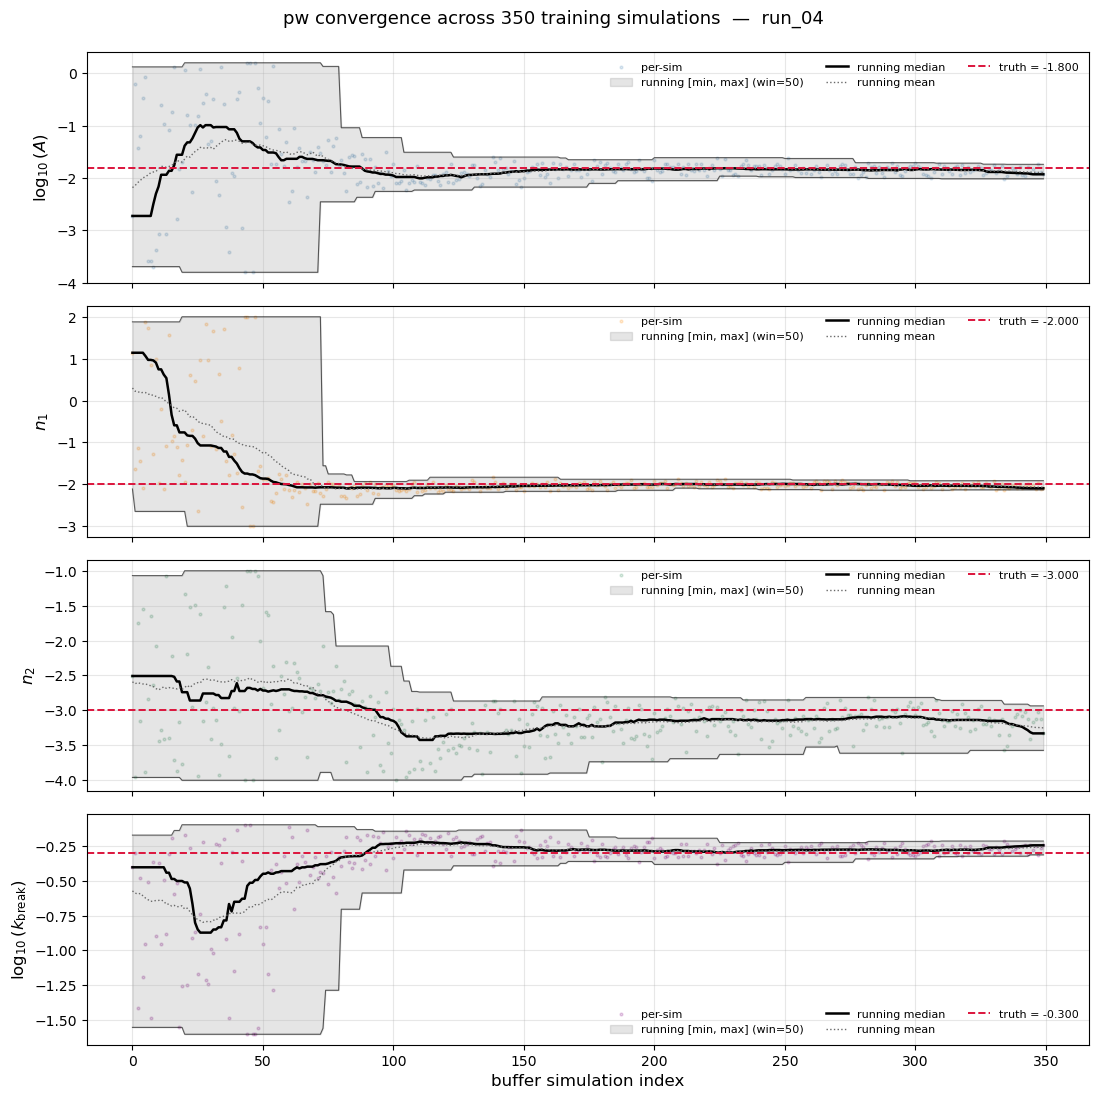

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/pw_convergence.pdf


In [12]:
# ── 4-D pw convergence across buffer simulations ──────────────────────────
# Rolling stats per parameter of [log10(A), n1, n2, log10(k_break)].
import numpy as np

def rolling(x, win, fn):
    win = max(1, min(win, len(x)))
    pad = win // 2
    xp  = np.pad(x, (pad, pad), mode="edge")
    return np.array([fn(xp[i:i+win]) for i in range(len(x))])

N    = len(pw_buffer)
idx  = np.arange(N)
WIN  = max(50, N // 40)

fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
colours = ["steelblue", "darkorange", "seagreen", "purple"]

for ax, col_idx, truth, ylabel, colour in zip(
    axes, range(4), true_pw, pw_names, colours
):
    x = pw_buffer[:, col_idx]
    stats = {
        "median": rolling(x, WIN, np.median),
        "mean":   rolling(x, WIN, np.mean),
        "max":    rolling(x, WIN, np.max),
        "min":    rolling(x, WIN, np.min),
    }
    ax.scatter(idx, x, s=4, alpha=0.18, color=colour, label="per-sim")
    ax.fill_between(idx, stats["min"], stats["max"], color="black", alpha=0.10,
                    label=f"running [min, max] (win={WIN})")
    ax.plot(idx, stats["max"],    color="black",   lw=0.8, alpha=0.6)
    ax.plot(idx, stats["min"],    color="black",   lw=0.8, alpha=0.6)
    ax.plot(idx, stats["median"], color="black",   lw=1.8,         label="running median")
    ax.plot(idx, stats["mean"],   color="dimgray", lw=1.0, ls=":", label="running mean")
    ax.axhline(truth, color="crimson", lw=1.4, ls="--", label=f"truth = {truth:+.3f}")
    ax.set_ylabel(ylabel, fontsize=12)
    ax.legend(loc="best", fontsize=8, frameon=False, ncol=3)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("buffer simulation index", fontsize=12)
fig.suptitle(f"pw convergence across {N} training simulations  —  {label}",
             fontsize=13, y=0.995)
fig.tight_layout()
out = run_path / "pw_convergence.pdf"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

In [13]:
# ── Posterior δ GIF: 3 panels (true | sampled | difference) ────────────────
STRIDE = 15
make_df_gif(
    pw_post[::STRIDE],
    label="posterior",
    out_name=f"df_seed{SEED}_posterior_vs_true.gif",
)


Saved GIF: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/df_seed54_posterior_vs_true.gif  (6.4 MB, 100 frames, loop=0)


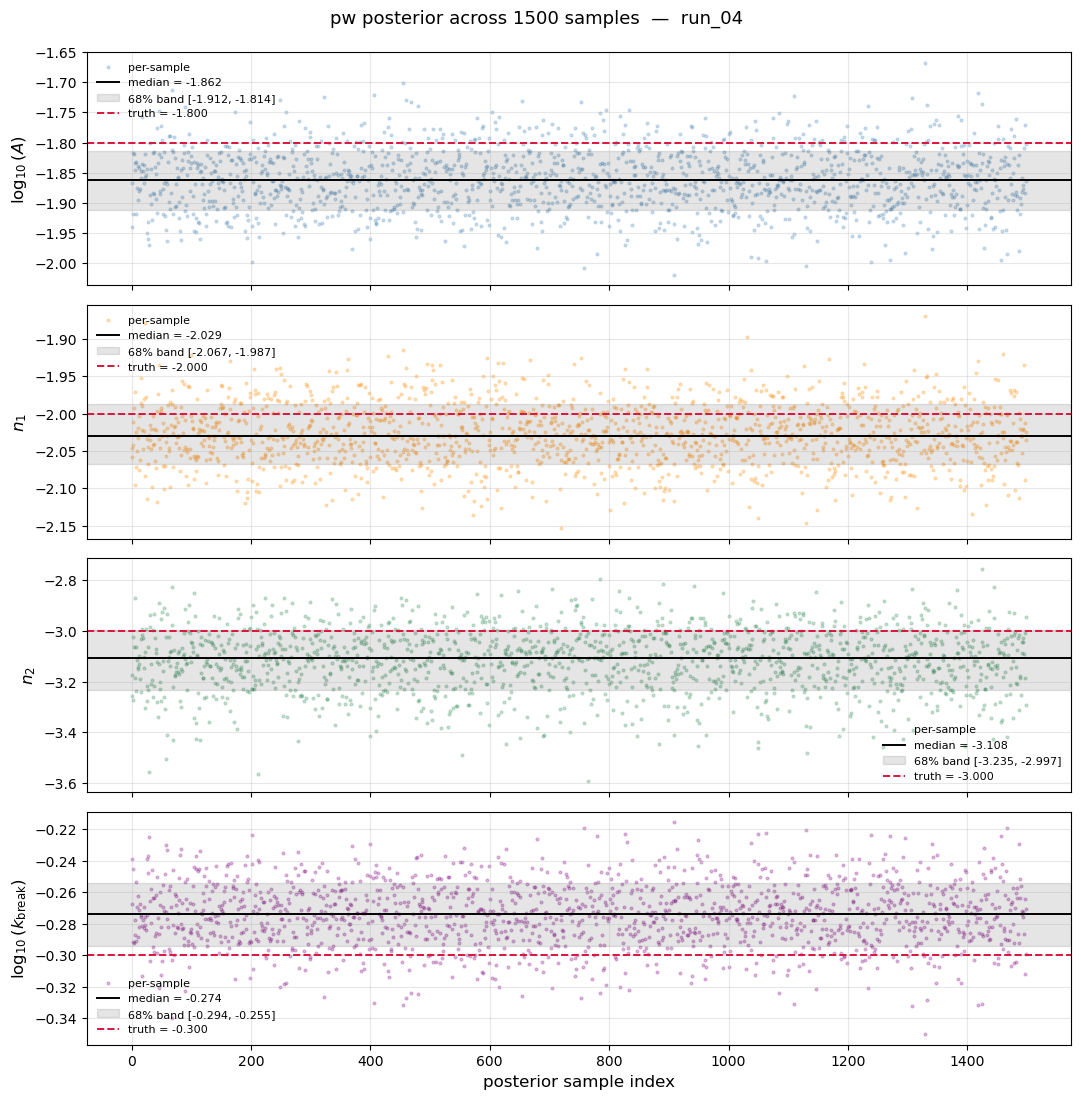

Saved: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/pw_posterior_scatter.pdf


In [14]:
# ── Posterior pw scatter: 4 panels for [log10(A), n1, n2, log10(k_break)] ──
import numpy as np

N    = len(pw_post)
idx  = np.arange(N)

fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
colours = ["steelblue", "darkorange", "seagreen", "purple"]

for ax, col_idx, truth, ylabel, colour in zip(
    axes, range(4), true_pw, pw_names, colours
):
    x      = pw_post[:, col_idx]
    med    = np.median(x)
    lo, hi = np.percentile(x, [16, 84])
    ax.scatter(idx, x, s=4, alpha=0.25, color=colour, label="per-sample")
    ax.axhline(med, color="black", lw=1.4, label=f"median = {med:+.3f}")
    ax.axhspan(lo, hi, color="black", alpha=0.10,
               label=f"68% band [{lo:+.3f}, {hi:+.3f}]")
    ax.axhline(truth, color="crimson", lw=1.4, ls="--",
               label=f"truth = {truth:+.3f}")
    ax.set_ylabel(ylabel, fontsize=12)
    ax.legend(loc="best", fontsize=8, frameon=False)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("posterior sample index", fontsize=12)
fig.suptitle(f"pw posterior across {N} samples  —  {label}", fontsize=13, y=0.995)
fig.tight_layout()
out = run_path / "pw_posterior_scatter.pdf"
plt.savefig(out, bbox_inches="tight")
plt.show()
print(f"Saved: {out}")

In [15]:
# ── Buffer S_dense GIF: 3 panels (true | dense | amplitude difference) ────
# uv_strided_buf was loaded once in the setup cell — no per-frame np.load here.
make_S_gif(
    uv_strided_buf,
    label="buffer",
    out_name="S_dense_buffer_vs_true.gif",
)


Saved GIF: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/S_dense_buffer_vs_true.gif  (3.1 MB, 18 frames, loop=0)


In [16]:
# ── Buffer P(k) GIF: 3 panels (true | sampled | ratio) ────────────────────
# pk_strided_buf was loaded in the same pass as uv_strided_buf in setup —
# no per-frame np.load here, no second loop over the same files.
make_pk_gif(
    pk_strided_buf,
    pw_strided_buf,
    label="buffer",
    out_name="pk_buffer_vs_true.gif",
)


Saved GIF: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/pk_buffer_vs_true.gif  (0.4 MB, 18 frames, loop=0)


In [17]:
# ── Posterior P(k) GIF: analytical broken-PL from each posterior pw_post ──
# Posterior NPZs don't store pk_df per sample, so this GIF is purely analytical:
# we evaluate P(k) = A·(k/k_break)^{n1 or n2} on `true_k` for every sampled pw.
# The truth analytical curve is overlaid for direct shape comparison.
STRIDE_POST_PK = 15
make_pk_post_gif(
    pw_post[::STRIDE_POST_PK],
    label="posterior",
    out_name="pk_posterior_analytical.gif",
)

Saved GIF: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar/output/run_04/pk_posterior_analytical.gif  (1.6 MB, 100 frames, loop=0)
